## Basic trip over a single edge
In this notebook, we set up a basic simulation where one vessel moves over a 1D network path. The example aims to provide a basic understanding of some key OpenTNSim core functions and shows what a basic OpenTNSim model run looks like. 

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from pyproj import Geod
from shapely.geometry import Point

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# OpenTNSim mixins and utils
from opentnsim.core import Identifiable, Movable
from opentnsim.core.utils import create_object, inspect_object
from opentnsim.graph.calculations import calculate_distance_along_path
from opentnsim.graph.mixins import Graph
from opentnsim.model import Simulation

# package(s) needed for inspecting the output
import pandas as pd

print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### 0. Create environment
First, we have to create an environment in the SimPy-package:

In [2]:
simulation = Simulation()
env = simulation.env

#### 1. Create graph
Next, we create a network (a graph) along which the vessel can move. For this case we create a single edge of 100 km exactly. We first calculate our geographic coordinates:

In [3]:
graph = Graph()

In [4]:
# initialize geodetic calculator with WGS84 ellipsoid
geod = Geod(ellps="WGS84")

# starting point (longitude, latitude)
lon0, lat0 = 0, 0

# compute the other point 100 km East from Point 0
lon1, lat1, _ = geod.fwd(lon0, lat0, 90, 100000) # East from Point 0

We add these coordinates as nodes to a NetworkX-package graph:

In [5]:
# define nodes with their geographic coordinates
graph.add_node(name = '0', geometry = Point(lon0, lat0))
graph.add_node(name = '1', geometry = Point(lon1, lat1))

We now need to add edges between the nodes:

In [6]:
# create list of edges
edges = [("0", "1")] 

# add edges
for edge in edges:
    graph.add_edge(edge)

We can now plot our graph:

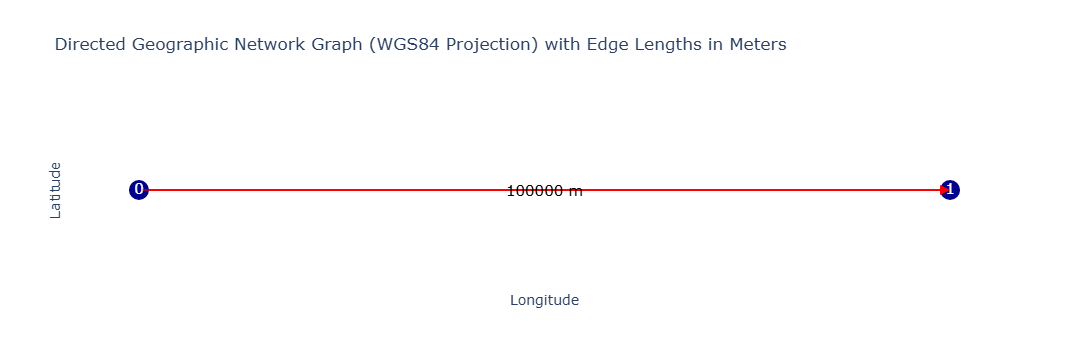

In [7]:
graph.plot()

We add the graph to our environment:

In [8]:
simulation.add_graph(graph)

#### 2. Create vessel
Next we have to create a Vessel-object (our vessel) that will move over the graph:

In [9]:
# make your preferred Vessel class out of available mix-ins.
Vessel = create_object(
    "Vessel", 
    (
        Identifiable, # allows to give the object a name and a random ID,
        Movable,      # allows the object to move, with a fixed speed, while logging this activity
    ), 
)

We can inspect the object to determine which inputs are required and optional:

In [10]:
inspect_object(Vessel)

,parameter,class,status
0,name,Identifiable,required
1,v,Movable,required
2,env,SimpyObject,required
3,route OR origin + destination,Vessel,required (one alternative)
4,id,Identifiable,optional
5,node,Locatable,optional
6,geometry,Movable,optional
7,destination,Routable,optional
8,origin,Routable,optional
9,route,Routable,optional


We define the required input (we define an origin and a destination):

In [11]:
data_vessel = {
    "env": env,                                                   # required by SimpyObjet
    "name": "Vessel",                                             # required by Identifiable
    "origin": "0",                                                # required by Routeable
    "destination": "1",                                           # required by Routeable
    "v": 3,                                                       # required by Movable, 3 m/s to check if the distance is covered in the expected time
} 

And create the vessel object:

In [12]:
# create an instance of the Vessel class using the input dict data_vessel
vessel = Vessel(**data_vessel)

Last, we have to define a mission for the vessel:

In [13]:
def mission(env, vessel):
    """
    Method that defines the mission of the vessel. 
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    while True:
        yield from vessel.move()
        if vessel.geometry == nx.get_node_attributes(env.graph, "geometry")[vessel.route[-1]]:
            break

And add vessel to the simulation:

In [14]:
simulation.add_vessel(vessel, mission)

#### 3. Run simulation
We now run the environment

In [15]:
simulation.run()

#### 4. Inspect output
We can now inspect  the simulation output by inspecting the _vessel.logbook_. Note that the _Log_ mix-in was included when we added _Movable_. The _vessel.logbook_ keeps track of the moving activities of the vessel. For each discrete event OpenTNSim logs an event message, the start/stop time and the location. The _vessel.logbook_ is of type dict. For convenient inspection it can be loaded into a Pandas dataframe. 

In [16]:
# load the logbook data into a dataframe
df = pd.DataFrame.from_dict(vessel.logbook)

print("'{}' logbook data:".format(vessel.name))  
print('')

display(df)

trip_distance = calculate_distance_along_path(env.graph, vessel.route)
trip_duration = datetime.timedelta.total_seconds(vessel.logbook[-1]['Timestamp'] - vessel.logbook[0]['Timestamp'])

print("'{}' travelled a distance of {:.1f} meters".format(vessel.name, trip_distance))
print("'{}' took {:.1f} seconds to arrive at its destination".format(vessel.name, trip_duration))  
print("'{}' travelled at an average speed of {:.1f} meters per second".format(vessel.name, trip_distance/trip_duration))
print('')
print('')

'Vessel' logbook data:



,Message,Timestamp,Value,Geometry
0,Sailing from node 0 to node 1 start,2026-10-27 13:21:18.000000,0.0,POINT (0 0)
1,Sailing from node 0 to node 1 stop,2026-10-27 22:36:51.333333,100000.0,POINT (0.8983152841195217 0)


'Vessel' travelled a distance of 100000.0 meters
'Vessel' took 33333.3 seconds to arrive at its destination
'Vessel' travelled at an average speed of 3.0 meters per second




The inspection of the logbook data shows that Vessel moved from its origin (*Node 0*) to its destination (*Node 1*). The print statements show that the length of the route from *Node 0* to *Node 1* is exactly 100 km. At a given speed of 1 m/s the trip duration should be exactly 100000 seconds, as is indeed shown to be the case.